In [ ]:
# Checked (final)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from metricsCalculation import DataPreparationUtils as utils

In [2]:
listOf1ServerLogFolders = {
    '../data/1_server/5_clients': 5,
    '../data/1_server/10_clients': 10,
    '../data/1_server/15_clients': 15,
    '../data/1_server/20_clients': 20,
    '../data/1_server/25_clients': 25,
    '../data/1_server/30_clients': 30,
}

listOf3ServerLogFolders = {
    '../data/3_server/5_clients': 5,
    '../data/3_server/10_clients': 10,
    '../data/3_server/15_clients': 15,
    '../data/3_server/20_clients': 20,
    '../data/3_server/25_clients': 25,
    '../data/3_server/30_clients': 30,
}

listOf5ServerLogFolders = {
    '../data/5_server/5_clients': 5,
    '../data/5_server/10_clients': 10,
    '../data/5_server/15_clients': 15,
    '../data/5_server/20_clients': 20,
    '../data/5_server/25_clients': 25,
    '../data/5_server/30_clients': 30,
}

In [3]:
dfCS1Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)'])

for (logFolder, clientNumber) in listOf1ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    median = dfWithCsMetricDescribe.iat[5,2]

    dfCS1Server.loc[len(dfCS1Server)] = [clientNumber, median]

dfCS3Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)'])

for (logFolder, clientNumber) in listOf3ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    median = dfWithCsMetricDescribe.iat[5,2]

    dfCS3Server.loc[len(dfCS3Server)] = [clientNumber, median]

dfCS5Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'CS (Median)'])

for (logFolder, clientNumber) in listOf5ServerLogFolders.items():
    dfClientSentLog = utils.readInClientLogsForScenario(logFolder)[0]
    dfServerConsumerLog = utils.readInServerLogsForScenario(logFolder)[1]

    dfWithCsMetric = utils.generateMetricCS(dfClientSentLog, dfServerConsumerLog)

    dfWithCsMetricDescribe = dfWithCsMetric.describe()
    median = dfWithCsMetricDescribe.iat[5,2]

    dfCS5Server.loc[len(dfCS5Server)] = [clientNumber, median]

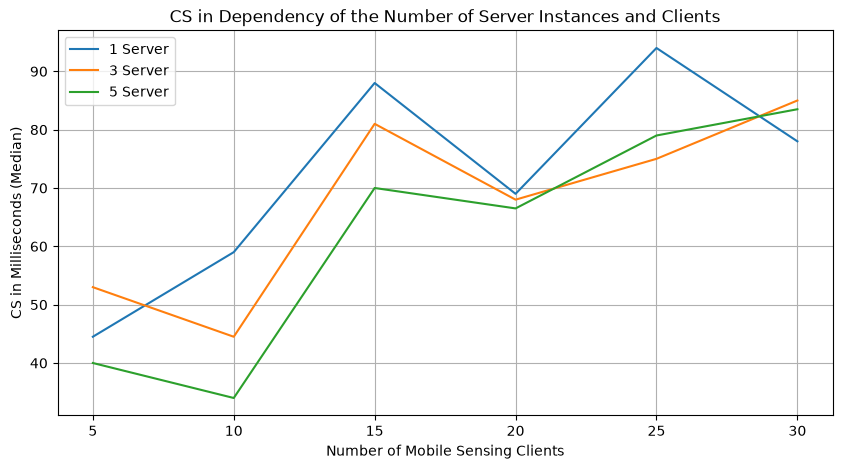

In [4]:
figure = plt.figure()

plt.plot(dfCS1Server['Number of Mobile Sensing Clients'], dfCS1Server['CS (Median)'], label='1 Server')
plt.plot(dfCS3Server['Number of Mobile Sensing Clients'], dfCS3Server['CS (Median)'], label='3 Server')
plt.plot(dfCS5Server['Number of Mobile Sensing Clients'], dfCS5Server['CS (Median)'], label='5 Server')

plt.title("CS in Dependency of the Number of Server Instances and Clients")
plt.xlabel("Number of Mobile Sensing Clients")
plt.ylabel("CS in Milliseconds (Median)")

plt.grid()
plt.legend()

figure.set_figwidth(10)
figure.set_figheight(5)

plt.show()